In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
from matplotlib import pyplot as plt
from pathlib import Path

# Do we think the same thing is happening in all of these countries?

This is a hypothetical dataset representing pesticide residues above a safety threshold vs. percentage of organic farms in different countries. How can we tell if trends are consistent across countries?

In [2]:
for file in Path('.').glob("*.csv"):
    df = pd.read_csv(file)
    x, y = df['x'], df['y']
    x_mean = np.mean(x)
    y_mean = np.mean(y)
    coeff = np.polyfit(x, y, deg=1)
    corr = np.corrcoef(x, y)[0, 1]
    
    print(f"x_mean={x_mean:.3f}, y_mean={y_mean:.3f}, linear regression fr(x)={coeff[1]:.1f} {coeff[0]:.2f} x, r = {corr:.3f} ")

x_mean=54.269, y_mean=47.835, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.266, y_mean=47.835, linear regression fr(x)=53.4 -0.10 x, r = -0.064 
x_mean=54.261, y_mean=47.830, linear regression fr(x)=53.2 -0.10 x, r = -0.062 
x_mean=54.267, y_mean=47.840, linear regression fr(x)=53.3 -0.10 x, r = -0.063 
x_mean=54.269, y_mean=47.831, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.268, y_mean=47.836, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.267, y_mean=47.838, linear regression fr(x)=53.8 -0.11 x, r = -0.068 
x_mean=54.266, y_mean=47.831, linear regression fr(x)=53.8 -0.11 x, r = -0.069 
x_mean=54.270, y_mean=47.837, linear regression fr(x)=53.9 -0.11 x, r = -0.069 
x_mean=54.263, y_mean=47.832, linear regression fr(x)=53.5 -0.10 x, r = -0.064 
x_mean=54.267, y_mean=47.832, linear regression fr(x)=53.6 -0.11 x, r = -0.067 
x_mean=54.260, y_mean=47.840, linear regression fr(x)=53.6 -0.11 x, r = -0.066 
x_mean=54.260, y_mean=47.840, linear reg

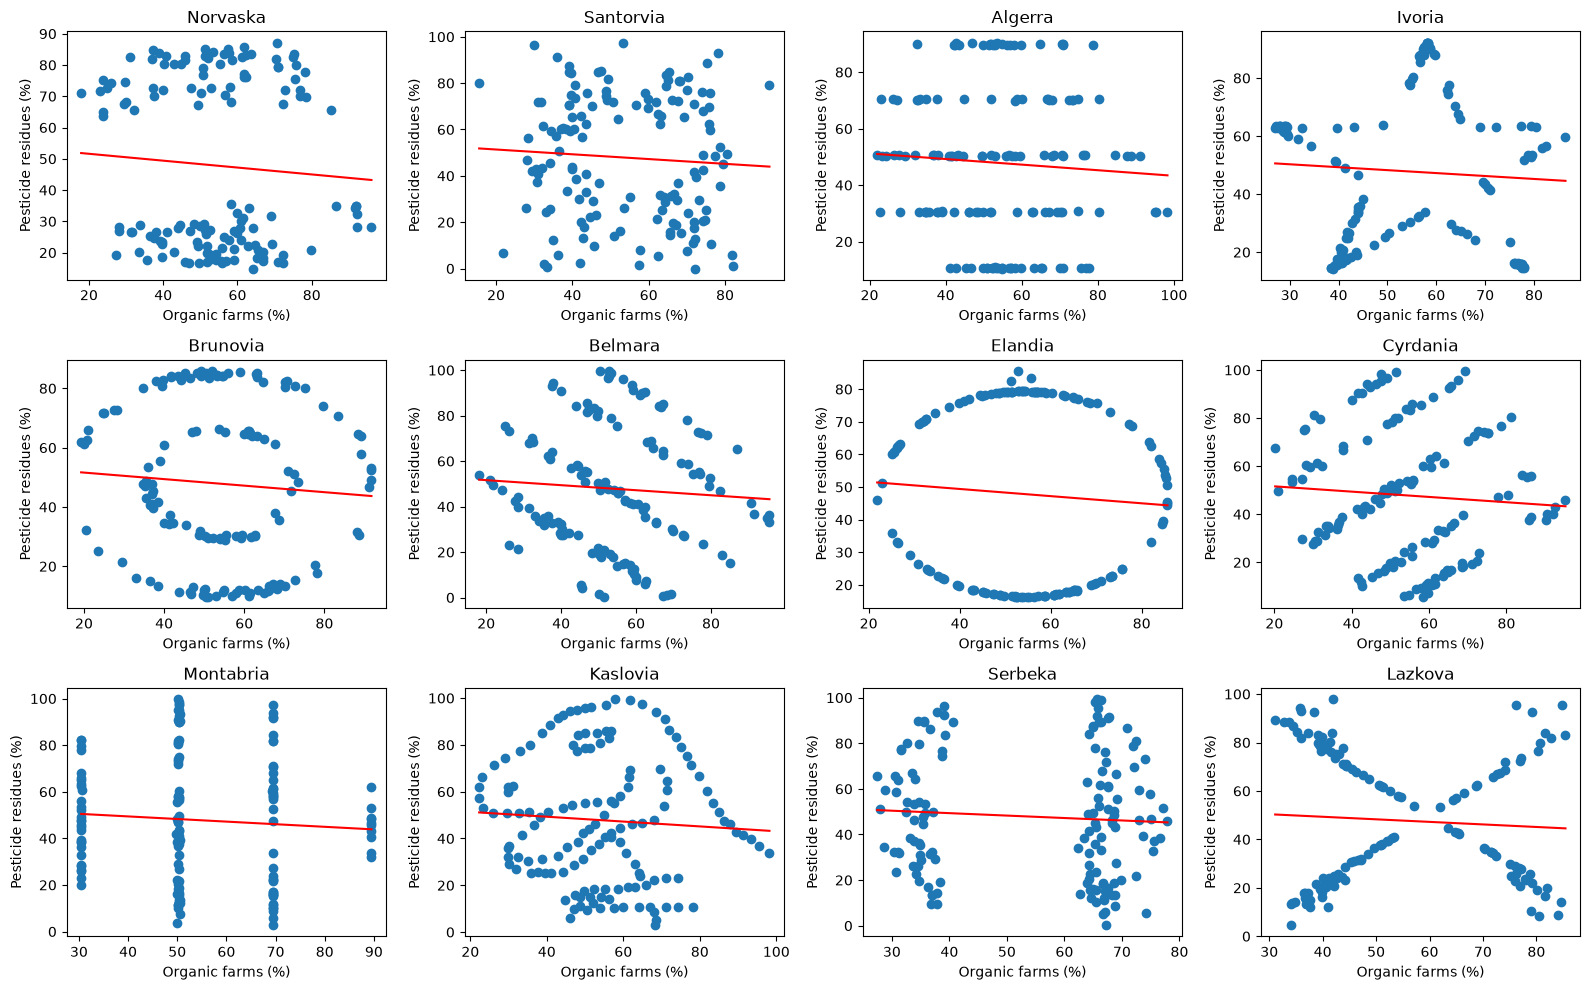

In [ ]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for ax, file in zip(axes.flat, Path('.').glob("*.csv")):
    df = pd.read_csv(file)
    x, y = df['x'], df['y']

    coeff = np.polyfit(x, y, deg=1)

    ax.scatter(x, y)

    x_line = np.linspace(x.min(), x.max(), 100)
    y_line = np.polyval(coeff, x_line)

    ax.plot(x_line, y_line, color='red')

    ax.set_title(file.stem)
    ax.set_xlabel("Organic farms (%)")
    ax.set_ylabel("Pesticide residues (%)")

plt.tight_layout()
plt.show()

In [4]:
results = []

for file in Path('.').glob("*.csv"):
    df = pd.read_csv(file)
    x, y = df['x'], df['y']

    coeff = np.polyfit(x, y, deg=1)
    corr = np.corrcoef(x, y)[0, 1]

    results.append({
        'Country': file.stem,
        'Slope': coeff[0],
        'Intercept': coeff[1],
        'Correlation': corr,
        'R_squared': corr**2
    })

results_df = pd.DataFrame(results)

print(results_df.round(3))

      Country  Slope  Intercept  Correlation  R_squared
0    Norvaska -0.110     53.809       -0.069      0.005
1   Santorvia -0.103     53.425       -0.064      0.004
2     Algerra -0.099     53.211       -0.062      0.004
3      Ivoria -0.101     53.327       -0.063      0.004
4    Brunovia -0.110     53.809       -0.069      0.005
5     Belmara -0.111     53.850       -0.069      0.005
6     Elandia -0.110     53.797       -0.068      0.005
7    Cyrdania -0.110     53.813       -0.069      0.005
8   Montabria -0.112     53.891       -0.069      0.005
9    Kaslovia -0.104     53.453       -0.064      0.004
10    Serbeka -0.107     53.635       -0.067      0.004
11    Lazkova -0.105     53.554       -0.066      0.004
12   Marensia -0.097     53.098       -0.060      0.004
